# Generative Adversarial Networks (GANs)

**Gudsky Research Foundation · Research Intake 2026 · Day 34**
**Module:** Computer Vision Fundamentals

This notebook is a study companion to the Day 34 guide. It covers the GAN framework, training dynamics, common failure modes, architectural guidelines, conditional and image-to-image GANs, progressive and style-based GANs, evaluation metrics, and ethics. It ends with a small runnable GAN experiment and the PP14 assignment brief.

### Learning objectives
- Explain how a generative model differs from a discriminative one.
- Write the GAN minimax objective and explain its Nash equilibrium.
- Diagnose mode collapse, training instability, and an overpowered discriminator.
- Choose between DCGAN, conditional GAN, pix2pix, CycleGAN, Progressive GAN, and StyleGAN for a task.
- Evaluate generators with Inception Score, FID, and precision-recall, and state their limits.

### Contents
1. From discriminative to generative
2. The GAN framework
3. Training dynamics and adversarial loss
4. Common GAN failure modes
5. DCGAN and architectural guidelines
6. Conditional GANs
7. Image-to-image translation
8. Progressive and high-resolution GANs
9. Evaluating generative models
10. Research frontiers and ethics
11. Common pitfalls checklist
12. Glossary
13. Hands-on: a toy GAN experiment
14. Assignment: PP14 image generation with GANs
15. References

## 1. From discriminative to generative

Days 26 to 33 covered **discriminative** tasks. Each maps an input image to a label, a box, or a mask, and a correct answer exists for each input.

A **generative** model produces new images from random noise. There is no single correct output to compare against, so the model is judged on whether its samples look as if they came from the training distribution.

| | Discriminative (Days 26–33) | Generative (Day 34 onward) |
|---|---|---|
| Input | Image | Random noise $z$ |
| Output | Label, box, or mask | New image |
| Ground truth | Exists for each input | None |
| Typical loss | Cross-entropy, IoU-based | Adversarial (GAN), likelihood-based or denoising (diffusion, Day 35) |
| Evaluation | Accuracy, mAP, mIoU | FID, Inception Score, precision-recall, human review |

> **Capability note.** A well-trained GAN can produce photorealistic faces of people who do not exist. The same capability is the reason synthetic media detection matters (Section 10).

## 2. The GAN framework

Goodfellow et al. (2014) framed generation as a game between two networks:

- **Generator** $G$ takes noise $z \sim p_z$ and produces a fake image $G(z)$.
- **Discriminator** $D$ takes an image and outputs the probability that it is real.

The two networks train together. Each one's improvement changes the other's target.

The value function is

$$
\min_G \max_D V(D, G) = \mathbb{E}_{x \sim p_{\text{data}}}\big[\log D(x)\big] + \mathbb{E}_{z \sim p_z}\big[\log\big(1 - D(G(z))\big)\big]
$$

For a fixed generator, the optimal discriminator is

$$
D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_G(x)}
$$

When $p_G = p_{\text{data}}$, $D^*(x) = \tfrac{1}{2}$ everywhere. This is the **Nash equilibrium**: the discriminator does no better than chance. Real training rarely reaches this point cleanly (Section 3).

**Realism is relative.** The discriminator learns what is "real" only from the training data. A face GAN has no basis for judging child faces, so its notion of realism is relative to its training distribution.

## 3. Training dynamics and adversarial loss

### 3.1 The original GAN loss
The discriminator is trained with binary cross-entropy: real images are labeled 1 and generated images are labeled 0. Training alternates two steps per iteration:

1. **Discriminator step:** freeze $G$ and update $D$ on a batch of real and generated images.
2. **Generator step:** freeze $D$ and update $G$ using $D$'s judgment of fresh generated images.

Freezing the wrong network in either step is a common implementation error that raises no explicit error message.

### 3.2 Why GANs are hard to train
Classification and detection losses fall steadily as a model improves. GAN losses do not have this property. A falling generator loss can mean that the discriminator has become worse, not that the generator has improved. **Neither loss curve alone shows progress.** Watch generated samples throughout training.

### 3.3 Balancing generator and discriminator
If either network becomes too strong early, the weaker network gets almost no useful gradient. The right update ratio between the two networks depends on the dataset and architecture and is found empirically.

### 3.4 Non-saturating loss
Early in training, the original generator loss $\log(1 - D(G(z)))$ has a very small gradient when $D$ confidently rejects fakes. The standard practical fix is the **non-saturating** generator loss:

$$
\max_G \; \mathbb{E}_{z \sim p_z}\big[\log D(G(z))\big] \quad \Longleftrightarrow \quad \min_G \; -\mathbb{E}_{z \sim p_z}\big[\log D(G(z))\big]
$$

The Hands-on section below implements this form.

## 4. Common GAN failure modes

Each failure mode has a different cause, a different diagnostic signal, and a different fix. Treating them as one generic "GAN training is unstable" problem leads to wrong fixes.

| Failure mode | Cause | Diagnostic signal | Standard response |
|---|---|---|---|
| **Mode collapse** (4.1) | Generator finds a few outputs that fool $D$ and produces only near-identical variants. The loss has no explicit diversity term. | Low diversity across different noise inputs, visible in a grid of samples. Loss curves can look normal. | Check the architecture and loss settings; inspect samples; consider minibatch-diversity or related regularizers (see references). |
| **Training instability** (4.2) | The two networks keep undoing each other's progress and never settle. | Sample quality itself oscillates or degrades over training, not just the loss values. | DCGAN guidelines (Section 5); lower learning rates; balance update ratios (3.3). |
| **Overpowered discriminator** (4.3) | $D$ separates real from fake too easily, so $G$ gets almost no gradient. | $D$'s average confidence on generated samples stays near 0 for many iterations, while sample quality plateaus. | Non-saturating loss (3.4); slow $D$ relative to $G$ (3.3). |

**Diagnose before fixing.** Applying the wrong fix (for example, slowing the discriminator when the real problem is mode collapse) wastes training time.

## 5. DCGAN and architectural guidelines

Radford et al. (2015) did not change the adversarial objective. They identified architectural choices that made GAN training reliable enough to use in practice. These guidelines became the standard starting template:

- **Strided convolutions** replace pooling. The discriminator uses strided convolutions to downsample. The generator uses strided transposed convolutions to upsample.
- **Batch normalization** is used in both networks, except at the generator's output layer and the discriminator's input layer.
- **No fully-connected hidden layers.** The only exceptions are the generator's first layer, which projects the noise vector into a small spatial map, and in some formulations the discriminator's final classification layer.
- **Activations:** ReLU in the generator (with tanh at the output) and LeakyReLU in the discriminator.

A common mistake is keeping one fully-connected layer in the middle of the generator's upsampling path. This discards the spatial structure the convolutions have already built.

## 6. Conditional GANs

A conditional GAN (Mirza & Osindero, 2014) gives both networks an extra input $y$, such as a class label:

$$
G(z, y) \rightarrow x, \qquad D(x, y) \rightarrow \text{probability that } x \text{ is real and matches } y
$$

This allows controllable generation: ask for a "7" instead of sampling any digit. The discriminator must judge both realism and whether the image matches its label. A real cat image labeled "dog" should be judged fake.

Conditioning is the one structural change in PP14 Approach B, so comparing it with the unconditional Approach A isolates what conditioning buys.

## 7. Image-to-image translation

### 7.1 pix2pix (paired)
pix2pix (Isola et al., 2017) is a conditional GAN whose condition is a full source image, such as a sketch, a map, or a daytime scene. It requires aligned pairs of source and target images. Its training objective combines the adversarial loss with a pixel-level L1 reconstruction term:

$$
\mathcal{L}_{\text{pix2pix}} = \mathcal{L}_{\text{cGAN}}(G, D) + \lambda\, \mathbb{E}_{x,y}\big[\lVert y - G(x) \rVert_1\big]
$$

Its generator is a U-Net. The skip connections preserve fine spatial detail from the input, so the output stays aligned with the source.

### 7.2 CycleGAN (unpaired)
CycleGAN (Zhu et al., 2017) removes the paired-data requirement. It trains two generators, $G: X \to Y$ and $F: Y \to X$, with a **cycle-consistency** loss:

$$
\mathcal{L}_{\text{cyc}} = \mathbb{E}_{x}\big[\lVert F(G(x)) - x \rVert_1\big] + \mathbb{E}_{y}\big[\lVert G(F(y)) - y \rVert_1\big]
$$

Translating an image to the other domain and back should recover the original. This signal needs no ground-truth pairs. The cycle-consistency weight matters: too low and translations drift from the input; too high and the model stays close to identity.

### 7.3 Applications
Style transfer, sketch-to-photo generation, and day-to-night or summer-to-winter scene translation. Translation can also be used as data augmentation, producing new, semantically coherent variations of a dataset. This goes beyond the fixed rotations and color jitter of standard augmentation.

## 8. Progressive and high-resolution GANs

Training directly at high resolution is unstable. The discriminator can detect fine texture differences long before the generator learns coherent large-scale structure.

### 8.1 Progressive GAN (Karras et al., 2018)
Training starts at 4×4 and grows both networks to 8×8, 16×16, and so on. New layers are blended in gradually: a fade-in weight rises from 0 to 1 over a transition period. This avoids a sudden shock to already-learned weights.

### 8.2 StyleGAN (Karras et al., 2019)
StyleGAN maps the noise vector through a separate **mapping network** into an intermediate latent space. It then injects style information at every resolution level. Early injections control coarse attributes such as pose and face shape. Later injections control fine attributes such as hair texture and skin tone. This produces a **disentangled** latent space that supports controllable editing. It also makes realistic synthetic faces easier to produce, which links to the ethics discussion in Section 10.

## 9. Evaluating generative models

Accuracy, mAP, and mIoU do not apply here because there is no ground truth to compare a sample against.

### 9.1 Inception Score (Salimans et al., 2016)

$$
\text{IS}(G) = \exp\Big(\mathbb{E}_{x \sim p_G}\big[D_{\text{KL}}\big(p(y \mid x) \,\Vert\, p(y)\big)\big]\Big)
$$

Here $p(y \mid x)$ is a pretrained classifier's prediction for a generated image. A high score requires confident per-image predictions and a varied overall class distribution. IS never compares generated images with real data, so it can score well on images that look nothing like the training set.

### 9.2 Fréchet Inception Distance (Heusel et al., 2017)
FID compares the mean $\mu$ and covariance $\Sigma$ of deep features (typically from an Inception network) for real images $r$ and generated images $g$:

$$
\text{FID} = \lVert \mu_r - \mu_g \rVert_2^2 + \operatorname{Tr}\Big(\Sigma_r + \Sigma_g - 2\big(\Sigma_r \Sigma_g\big)^{1/2}\Big)
$$

Lower is better. FID needs no labels, but it is sensitive to the number of samples. Small-sample FID values are not directly comparable with published values computed on much larger sets.

### 9.3 Qualitative and human evaluation
Metrics miss artifacts such as anatomically wrong details and stylistic mismatches. Direct inspection of samples and structured human judgment remain necessary.

### 9.4 Precision and recall for generative models (Kynkäänniemi et al., 2019)
- **Precision:** how much of the generated distribution falls inside the real distribution's support (sample realism).
- **Recall:** how much of the real distribution the generator covers (diversity).

A mode-collapsed generator can have high precision and low recall. FID alone can hide that distinction, so report precision and recall alongside FID.

### 9.5 Practical guidance for PP14
Within a single Colab T4 session, FID may be impractical for all three approaches. A consistent, structured qualitative comparison is an acceptable substitute, as long as the same criteria apply to every approach.

## 10. Research frontiers and ethics

**GANs versus diffusion models.** Day 35 covers diffusion models. GANs generate a sample in one forward pass and are fast at inference. They are notoriously hard to train. Diffusion models train more stably but usually take many sequential steps to sample. Neither is universally better; the choice depends on constraints.

**Deepfakes and consent.** Generative models can create synthetic media of real people without their knowledge or consent, and fabricated identities used for fraud. Synthetic media detection is an ongoing arms race, structurally similar to the adversarial game itself.

**Responsible use (baseline principles):**
- Label synthetic media clearly.
- Do not generate identifiable depictions of real people without explicit permission.
- Choose training data deliberately. A small dataset is not inherently safer than a large one.

**Beyond images.** GANs have been applied to audio, tabular data synthesis, and molecular generation, with domain-specific architectures.

## 11. Common pitfalls: debugging checklist

- [ ] Inspect generated samples directly and frequently, not only the loss curves.
- [ ] Before concluding training has failed, identify which failure mode (4.1, 4.2, or 4.3) is occurring.
- [ ] Confirm the non-saturating generator loss (3.4) is used, not the original minimax form.
- [ ] Confirm batch normalization follows the DCGAN guidelines (5.2), including the layers where it is omitted.
- [ ] For CycleGAN, tune the cycle-consistency weight deliberately.
- [ ] Watch for discriminator overfitting on a small dataset.
- [ ] Track the discriminator's average confidence on generated samples (a value near 0 for long stretches signals an overpowered discriminator).
- [ ] Fix random seeds, including the noise-sampling seed, when comparing runs.
- [ ] Do not compare your FID with published benchmark numbers computed under different conditions.

### Reproducibility
GAN training has every source of randomness that earlier days identified (weight initialization, data augmentation) plus the noise vector sampled for the generator. Run-to-run variance is a larger practical concern for GANs than for single-network models.

## 12. Glossary

| Term | Definition |
|---|---|
| **Generator** | Network that maps noise (and optionally a condition) to a synthetic image. |
| **Discriminator** | Network that classifies an image as real or generated. |
| **Minimax objective** | Training formulation in which $D$ maximizes and $G$ minimizes the same value function. |
| **Nash equilibrium** | Stable point where $p_G = p_{\text{data}}$ and $D = \tfrac{1}{2}$ everywhere. |
| **Non-saturating loss** | Generator objective $-\log D(G(z))$ that keeps gradients strong early in training. |
| **Mode collapse** | Generator produces a narrow range of outputs that fool the current discriminator. |
| **DCGAN guidelines** | Architectural conventions (strided convolutions, batch normalization, few dense layers, specific activations). |
| **Conditional GAN (cGAN)** | GAN in which both networks receive an extra input such as a class label. |
| **pix2pix** | Paired image-to-image translation with a conditional GAN and a U-Net generator. |
| **CycleGAN** | Unpaired translation trained with cycle-consistency loss. |
| **Cycle-consistency loss** | Requires that translating to another domain and back recovers the original image. |
| **Progressive GAN** | Training that grows resolution gradually, with fade-in of new layers. |
| **StyleGAN** | High-resolution GAN with a mapping network and style injection at each resolution. |
| **Inception Score (IS)** | Metric combining per-image classifier confidence with overall class diversity. |
| **FID** | Distance between real and generated feature distributions (lower is better). |
| **Precision / Recall (generative)** | Realism of samples / coverage of the real distribution. |

## 13. Hands-on: a toy GAN experiment

This experiment runs on CPU in a few seconds and needs no dataset download. The real data is a 1-D mixture of two Gaussians centered at −2 and +2. The generator must learn to produce samples from both modes.

Measured results come from running the code, not from this text. Check for mode collapse by counting how many generated samples fall near each mode. A balanced count suggests the generator covers both modes.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

def sample_real(n: int) -> torch.Tensor:
    # Mixture of two Gaussians with modes at -2 and +2 (std 0.3).
    component = torch.randint(0, 2, (n, 1)).float()
    centers = component * 4.0 - 2.0
    return centers + 0.3 * torch.randn(n, 1)

LATENT_DIM = 8
G = nn.Sequential(
    nn.Linear(LATENT_DIM, 64), nn.ReLU(),
    nn.Linear(64, 64), nn.ReLU(),
    nn.Linear(64, 1),
).to(device)

# The discriminator outputs logits. The sigmoid is folded into BCEWithLogitsLoss.
D = nn.Sequential(
    nn.Linear(1, 64), nn.LeakyReLU(0.2),
    nn.Linear(64, 64), nn.LeakyReLU(0.2),
    nn.Linear(64, 1),
).to(device)

opt_G = torch.optim.Adam(G.parameters(), lr=1e-3, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=1e-3, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()

BATCH = 128
STEPS = 3000
history = []

for step in range(STEPS):
    real = sample_real(BATCH).to(device)
    z = torch.randn(BATCH, LATENT_DIM, device=device)
    fake = G(z)

    # 1) Discriminator step: G is held fixed by detaching its output.
    d_real = D(real)
    d_fake = D(fake.detach())
    loss_D = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
    opt_D.zero_grad()
    loss_D.backward()
    opt_D.step()

    # 2) Generator step: non-saturating loss, -log D(G(z)).
    d_out = D(fake)
    loss_G = bce(d_out, torch.ones_like(d_out))
    opt_G.zero_grad()
    loss_G.backward()
    opt_G.step()

    history.append((loss_D.item(), loss_G.item()))

print(f"Finished {STEPS} steps on {device}.")
print(f"Last loss_D = {history[-1][0]:.3f}, last loss_G = {history[-1][1]:.3f}")

Finished 3000 steps on cuda.
Last loss_D = 1.372, last loss_G = 0.744


Real   : mean=+0.027  std=2.021  fraction<0=0.491
Fake   : mean=+0.025  std=2.136  fraction<0=0.509
Mode-coverage check: a fraction near 0.5 means both modes are covered; near 0 or 1 suggests mode collapse.


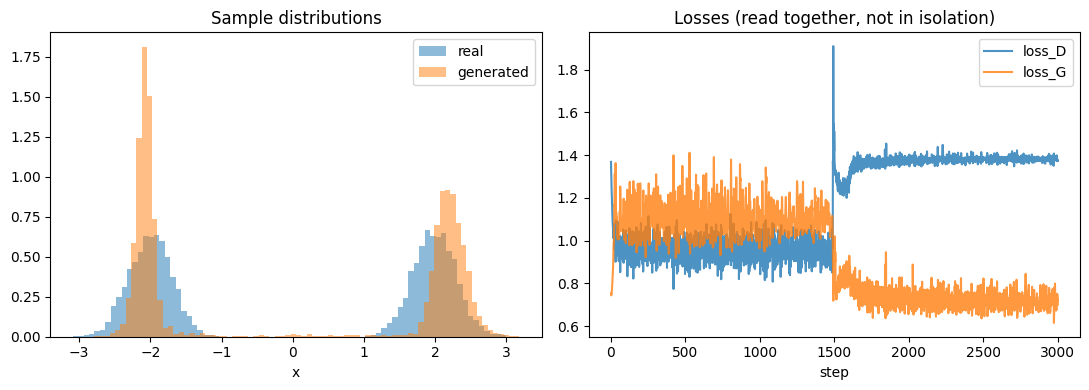

In [2]:
# Evaluate: distribution of generated samples versus real samples.
G.eval()
with torch.no_grad():
    fake_samples = G(torch.randn(5000, LATENT_DIM, device=device)).cpu().numpy().ravel()
    real_samples = sample_real(5000).numpy().ravel()

left_mode_frac = float((fake_samples < 0).mean())
print(f"Real   : mean={real_samples.mean():+.3f}  std={real_samples.std():.3f}  fraction<0={(real_samples < 0).mean():.3f}")
print(f"Fake   : mean={fake_samples.mean():+.3f}  std={fake_samples.std():.3f}  fraction<0={left_mode_frac:.3f}")
print("Mode-coverage check: a fraction near 0.5 means both modes are covered; near 0 or 1 suggests mode collapse.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(real_samples, bins=80, alpha=0.5, density=True, label="real")
axes[0].hist(fake_samples, bins=80, alpha=0.5, density=True, label="generated")
axes[0].set_title("Sample distributions")
axes[0].set_xlabel("x"); axes[0].legend()

d_hist = np.array(history)
axes[1].plot(d_hist[:, 0], label="loss_D", alpha=0.8)
axes[1].plot(d_hist[:, 1], label="loss_G", alpha=0.8)
axes[1].set_title("Losses (read together, not in isolation)")
axes[1].set_xlabel("step"); axes[1].legend()
plt.tight_layout()
plt.show()

### Exercises
1. Change `STEPS` to 200 and to 10000. How do the sample distributions change? Does the mode-coverage fraction move toward 0.5?
2. Replace the non-saturating generator loss with the original $\log(1 - D(G(z)))$ form (minimize it directly). Compare the early-training generator gradient.
3. Increase the discriminator's learning rate by 10×. Which failure mode from Section 4 does this resemble?
4. Remove `betas=(0.5, 0.999)` and compare stability over several seeds. Report the variance, not just one run.

## 14. Assignment: PP14 image generation with GANs

**Graded assignment.** Implement three approaches and compare them directly using the methodology in Section 9.5.

### A. Core requirements
1. **Approach A (vanilla / DCGAN):** unconditional generator trained from scratch, following the Section 5 guidelines.
2. **Approach B (conditional GAN):** class-conditioned GAN demonstrating controllable generation, on the same or a labeled variant of Approach A's dataset.
3. **Approach C (image-to-image translation):** pix2pix or CycleGAN on a paired or unpaired image-pair dataset.

Each approach must be **trained**, not run from a pretrained checkpoint at inference.

### B. Dataset
Use a compact, low-resolution dataset that fits a Colab T4. Approaches A and B use a small labeled set. Approach C uses a small paired or unpaired image-pair dataset. Document the dataset source and license.

### C. Deliverables
- [ ] Three working, trained pipelines (vanilla/DCGAN, conditional GAN, image-to-image translation) with documented training configurations
- [ ] Evaluation: FID where practical, otherwise a structured qualitative comparison applied consistently across all three approaches
- [ ] Training-stability observations for each approach against the Section 4 failure modes, including what was encountered and how it was diagnosed
- [ ] Comparison table or plot: sample quality, training stability, controllability, and compute cost
- [ ] Short written recommendation for when each approach fits a task, tied to the architectural tradeoffs in Sections 5–7

### D. Grading
Evaluation rigor and comparison quality carry the largest share of the grade. Three working but carelessly compared models will score lower than three adequately trained models compared rigorously, with honest reporting of failure modes and a dataset-grounded recommendation.

> **To be confirmed by course staff:** the source document does not state the submission method (for example, Colab link, GitHub repository, or both) or the numerical rubric weights. Do not treat the items above as final until those are published.

### E. Tips
- Budget time to diagnose at least one failure mode from Section 4.
- Verify the non-saturating loss is implemented before debugging a stalled generator.
- Save sample grids at regular checkpoints, not only at the end.
- Restart the Colab runtime or free GPU memory between approaches if they share a notebook session.

### F. Submission checklist
- [ ] Vanilla/DCGAN approach trained and evaluated
- [ ] Conditional GAN trained and evaluated, with controllability shown against the unconditional baseline
- [ ] Image-to-image approach (pix2pix or CycleGAN) trained and evaluated
- [ ] Evaluation protocol applied consistently across all three approaches
- [ ] Training-stability observations documented per approach
- [ ] Comparison table or plot uses your measured results, not placeholders
- [ ] Written recommendation connects results to Sections 5–7
- [ ] Code is documented, with a README explaining how to reproduce the results

## Summary of key takeaways
- Generative modeling has no ground truth, so evaluation differs fundamentally from Days 26–33.
- A GAN trains two networks adversarially with a minimax objective and no fixed external target.
- Neither GAN loss curve alone shows progress. Inspect samples.
- Mode collapse, instability, and an overpowered discriminator have different signatures and different fixes.
- DCGAN's architectural guidelines became the stable starting template for later GANs.
- Conditioning adds control. pix2pix uses paired data; CycleGAN uses cycle-consistency without pairs.
- FID is the standard metric. Pair it with precision/recall and human evaluation.
- GANs and diffusion models (Day 35) are two different answers to the same problem, trading training stability against sampling speed.

## 15. References

Primary sources for the methods in this notebook. Verify bibliographic details against the original publications before citing them in submitted work.

1. Goodfellow, I. et al. (2014). *Generative Adversarial Nets.* NeurIPS.
2. Mirza, M. & Osindero, S. (2014). *Conditional Generative Adversarial Nets.* arXiv:1411.1784.
3. Radford, A., Metz, L. & Chintala, S. (2015). *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks (DCGAN).* arXiv:1511.06434.
4. Salimans, T. et al. (2016). *Improved Techniques for Training GANs.* NeurIPS. (Inception Score.)
5. Isola, P. et al. (2017). *Image-to-Image Translation with Conditional Adversarial Networks (pix2pix).* CVPR.
6. Zhu, J.-Y. et al. (2017). *Unpaired Image-to-Image Translation using Cycle-Consistent Adversarial Networks (CycleGAN).* ICCV.
7. Heusel, M. et al. (2017). *GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium.* NeurIPS. (FID.)
8. Karras, T. et al. (2018). *Progressive Growing of GANs for Improved Quality, Stability, and Variation.* ICLR.
9. Karras, T., Laine, S. & Aila, T. (2019). *A Style-Based Generator Architecture for Generative Adversarial Networks.* CVPR. (StyleGAN.)
10. Kynkäänniemi, T. et al. (2019). *Improved Precision and Recall Metric for Assessing Generative Models.* NeurIPS.